# **D24AIML087_RSA_External_Practical_Examination**

In [6]:
!pip install fairlearn

In [7]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from fairlearn.metrics import (MetricFrame, selection_rate, true_positive_rate,
    false_positive_rate, demographic_parity_difference,
    demographic_parity_ratio, equalized_odds_difference)
from fairlearn.postprocessing import ThresholdOptimizer

## Task 1 — Load, clean and train

In [16]:
columns = ['age','workclass','fnlwgt','education','education-num',
           'marital-status','occupation','relationship','race','sex',
           'capital-gain','capital-loss','hours-per-week','native-country','income']

a = pd.read_csv('adult.data', names=columns, skipinitialspace=True)
b = pd.read_csv('adult.test', names=columns, skipinitialspace=True, skiprows=1)

df = pd.concat([a, b], ignore_index=True)

In [17]:
df.columns = df.columns.str.strip()

for col in df.select_dtypes(include='object'):
    df[col] = df[col].str.strip()
df = df.replace('?', pd.NA).dropna().reset_index(drop=True)
df['income'] = df['income'].astype(str).str.rstrip('.')
assert set(df['income'].unique()) == {'<=50K', '>50K'}
y = (df['income'] == '>50K').astype(int)
s = df['sex']
X = df.drop(columns=['income','sex'])

In [18]:
X_train, X_test, y_train, y_test, s_train, s_test = train_test_split(
    X, y, s, test_size=0.30, random_state=42, stratify=y)
num = X_train.select_dtypes(include='number').columns.tolist()
cat = X_train.select_dtypes(exclude='number').columns.tolist()

In [19]:
preprocess = ColumnTransformer([
    ('num', StandardScaler(), num),
    ('cat', OneHotEncoder(handle_unknown='ignore'), cat)])
model = make_pipeline(preprocess, LogisticRegression(max_iter=1000))
model.fit(X_train, y_train)
pred = model.predict(X_test)


print('Clean records:', len(df))
print('Accuracy:', accuracy_score(y_test, pred))

Clean records: 45222
Accuracy: 0.8458760227021449


## Tasks 2–3 — Group and fairness metrics

In [25]:
metrics = {'accuracy': accuracy_score, 'selection_rate': selection_rate,
           'TPR': true_positive_rate, 'FPR': false_positive_rate}

def audit(name, prediction):
    frame = MetricFrame(metrics=metrics, y_true=y_test,
                        y_pred=prediction, sensitive_features=s_test)
    dp = demographic_parity_difference(y_test, prediction, sensitive_features=s_test)
    ratio = demographic_parity_ratio(y_test, prediction, sensitive_features=s_test)
    eo = equalized_odds_difference(y_test, prediction, sensitive_features=s_test)
    print(name)
    print(frame.by_group.round(4))
    print('DP difference:', round(dp, 4))
    print('DP ratio:', round(ratio, 4))
    print('EO difference:', round(eo, 4))
    return {'Model': name, 'ACC': accuracy_score(y_test, prediction),
            'SEL_M': frame.by_group.loc['Male','selection_rate'],
            'SEL_F': frame.by_group.loc['Female','selection_rate'],
            'DP_DIFF': dp, 'DP_RATIO': ratio, 'EO_DIFF': eo}

baseline = audit('Baseline', pred)

Baseline
        accuracy  selection_rate     TPR     FPR
sex                                             
Female    0.9194          0.0788  0.4922  0.0245
Male      0.8107          0.2551  0.6059  0.0969
DP difference: 0.1763
DP ratio: 0.309
EO difference: 0.1137


## Task 4 — Demographic parity mitigation

In [10]:
dp_model = ThresholdOptimizer(estimator=model, constraints='demographic_parity',
                              objective='accuracy_score', prefit=True,
                              predict_method='predict_proba')
dp_model.fit(X_train, y_train, sensitive_features=s_train)
dp_pred = dp_model.predict(X_test, sensitive_features=s_test, random_state=42)
dp_result = audit('Demographic parity', dp_pred)

Demographic parity
        accuracy  selection_rate     TPR     FPR
sex                                             
Female    0.8973          0.1665  0.7745  0.0866
Male      0.7937          0.1623  0.4292  0.0419
DP difference: 0.0043
DP ratio: 0.9744
EO difference: 0.3453


## Task 5 — Equalized odds mitigation

In [11]:
eo_model = ThresholdOptimizer(estimator=model, constraints='equalized_odds',
                              objective='accuracy_score', prefit=True,
                              predict_method='predict_proba')
eo_model.fit(X_train, y_train, sensitive_features=s_train)
eo_pred = eo_model.predict(X_test, sensitive_features=s_test, random_state=42)
eo_result = audit('Equalized odds', eo_pred)

Equalized odds
        accuracy  selection_rate     TPR     FPR
sex                                             
Female    0.8834          0.1298  0.5569  0.0737
Male      0.8070          0.2146  0.5347  0.0702
DP difference: 0.0847
DP ratio: 0.6052
EO difference: 0.0222


## Task 6 — Comparison and plot

                       ACC   SEL_M   SEL_F  DP_DIFF  DP_RATIO  EO_DIFF
Model                                                                 
Baseline            0.8459  0.2551  0.0788   0.1763    0.3090   0.1137
Demographic parity  0.8272  0.1623  0.1665   0.0043    0.9744   0.3453
Equalized odds      0.8317  0.2146  0.1298   0.0847    0.6052   0.0222


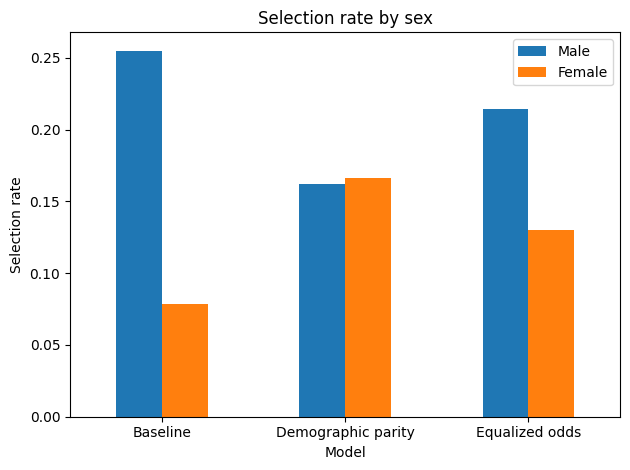

In [12]:
result = pd.DataFrame([baseline, dp_result, eo_result]).set_index('Model')
print(result.round(4).to_string())
result.to_csv('fairness_comparison.csv')
ax = result[['SEL_M','SEL_F']].rename(columns={'SEL_M':'Male','SEL_F':'Female'}).plot.bar(rot=0)
ax.set_ylabel('Selection rate')
ax.set_title('Selection rate by sex')
plt.tight_layout()
plt.savefig('selection_rate_by_sex.png', dpi=200)
plt.show()

In [13]:
print('Baseline disadvantaged group:', 'Female' if baseline['SEL_F'] < baseline['SEL_M'] else 'Male' if baseline['SEL_M'] < baseline['SEL_F'] else 'Neither')
print('80% rule:', 'Pass' if baseline['DP_RATIO'] >= 0.8 else 'Fail')
for row in [dp_result, eo_result]:
    print(row['Model'])
    print('Accuracy loss (percentage points):', round(100*(baseline['ACC']-row['ACC']), 2))
    print('DP gap change:', round(row['DP_DIFF']-baseline['DP_DIFF'], 4))
    print('EO gap change:', round(row['EO_DIFF']-baseline['EO_DIFF'], 4))

Baseline disadvantaged group: Female
80% rule: Fail
Demographic parity
Accuracy loss (percentage points): 1.86
DP gap change: -0.172
EO gap change: 0.2316
Equalized odds
Accuracy loss (percentage points): 1.42
DP gap change: -0.0916
EO gap change: -0.0916
